In [2]:
!pip install PythonTsa


In [4]:
from numpy import random
import pandas as pd
import matplotlib.pyplot as plt
from PythonTsa.plot_acf_pacf import acf_pacf_fig


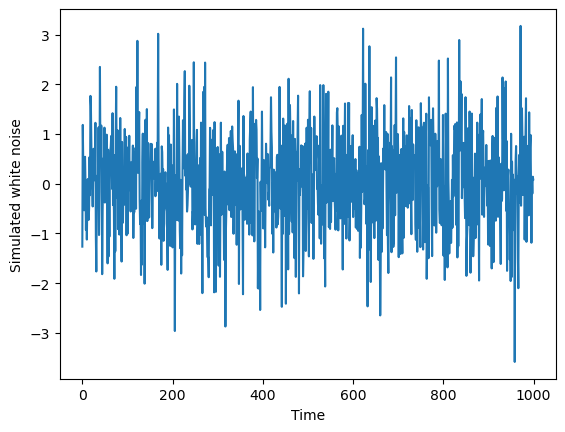

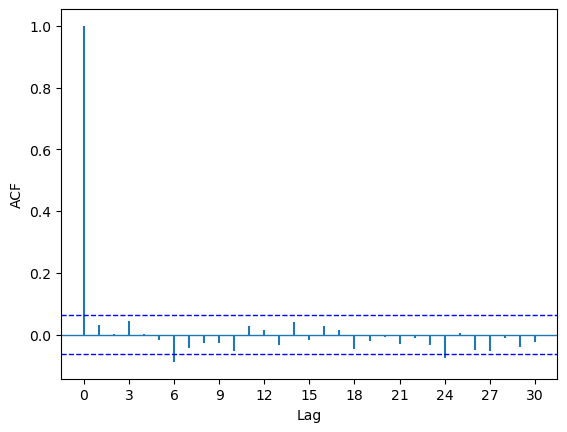

In [10]:

xts.plot()
plt.xlabel('Time')
plt.ylabel('Simulated white noise')

plt.savefig(
    'pyTSA_GaussWN_fig1-9.png',
    dpi=1200,
    bbox_inches='tight',
    transparent=True
)
plt.show()

acf_pacf_fig(xts, both=False, lag=30)

plt.savefig(
    'pyTSA_GaussWN_fig1-10.png',
    dpi=1200,
    bbox_inches='tight',
    transparent=True
)
plt.show()


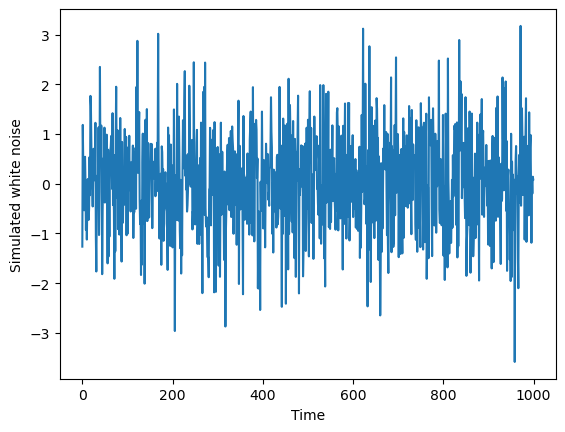

        x_t     L x_t   L^2 x_t
0 -1.264856       NaN       NaN
1  1.184281 -1.264856       NaN
2  0.355047  1.184281 -1.264856
3 -0.297943  0.355047  1.184281
4 -0.533484 -0.297943  0.355047
        x_t      Δx_t     Δ²x_t
0 -1.264856       NaN       NaN
1  1.184281  2.449137       NaN
2  0.355047 -0.829234 -3.278371
3 -0.297943 -0.652989  0.176245
4 -0.533484 -0.235541  0.417448


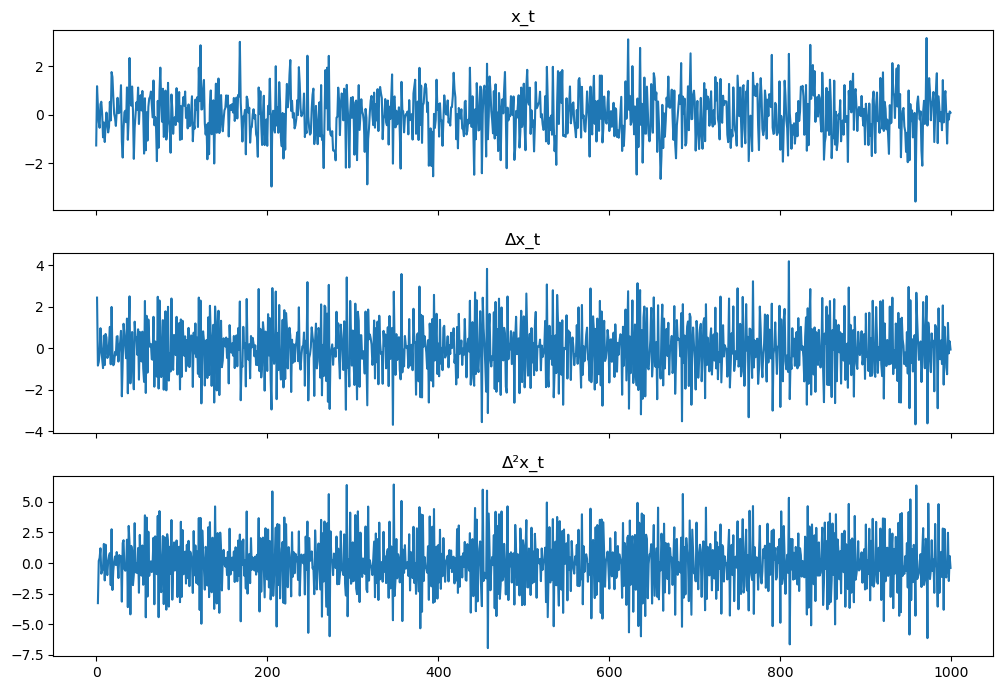

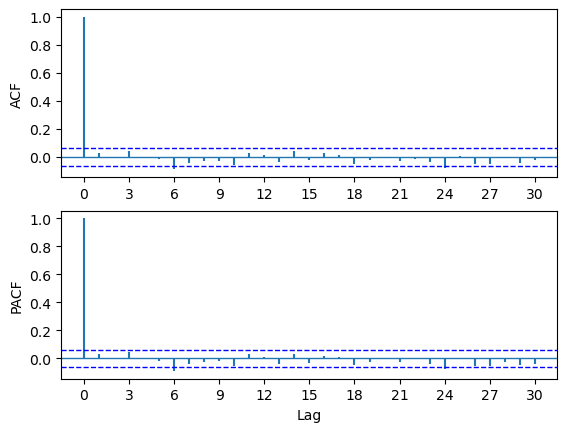

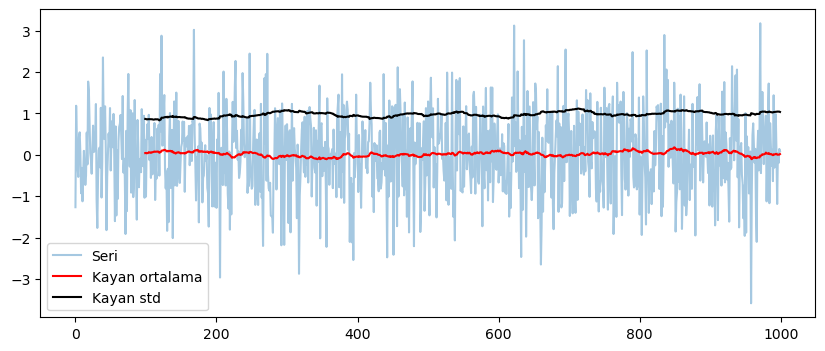

ADF: -13.8581  p-değeri: 6.807e-26  kritik: {'1%': np.float64(-3.43694584277544), '5%': np.float64(-2.8644520725172873), '10%': np.float64(-2.5683205291305176)}
KPSS: 0.0378  p-değeri: 0.1000


C:\Users\halha\AppData\Local\Temp\ipykernel_17132\1843144483.py:50: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  k = kpss(xts, regression='c', nlags='auto')


In [11]:
# pip install PythonTsa statsmodels pandas matplotlib numpy
from numpy import random
import pandas as pd
import matplotlib.pyplot as plt
from PythonTsa.plot_acf_pacf import acf_pacf_fig
from statsmodels.tsa.stattools import adfuller, kpss

random.seed(135)
x = random.normal(loc=0, scale=1, size=1000)
xts = pd.Series(x)

# 1) Zaman serisi grafiği
xts.plot()
plt.xlabel('Time'); plt.ylabel('Simulated white noise')
plt.show()

# 2) Lag işlemcisi: L x_t = x_{t-1}, L^2 x_t = x_{t-2}
lag1 = xts.shift(1)
lag2 = xts.shift(2)
print(pd.DataFrame({'x_t': xts, 'L x_t': lag1, 'L^2 x_t': lag2}).head())

# 3) Fark işlemcisi: Δx_t = (1-L)x_t = x_t - x_{t-1}
d1 = xts.diff(1)
d2 = xts.diff(1).diff(1)          # Δ^2
print(pd.DataFrame({'x_t': xts, 'Δx_t': d1, 'Δ²x_t': d2}).head())

fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
xts.plot(ax=ax[0], title='x_t')
d1.plot(ax=ax[1], title='Δx_t')
d2.plot(ax=ax[2], title='Δ²x_t')
plt.tight_layout(); plt.show()

# 4) ACF ve PACF (both=True ikisini birlikte çizer)
acf_pacf_fig(xts, both=True, lag=30)
plt.show()

# 5) Durağanlık
# Görsel: kayan ortalama ve standart sapma
plt.figure(figsize=(10, 4))
xts.plot(alpha=0.4, label='Seri')
xts.rolling(100).mean().plot(color='red', label='Kayan ortalama')
xts.rolling(100).std().plot(color='black', label='Kayan std')
plt.legend(); plt.show()

# ADF (H0: birim kök var, seri durağan değil)
adf = adfuller(xts, autolag='AIC')
print(f'ADF: {adf[0]:.4f}  p-değeri: {adf[1]:.4g}  kritik: {adf[4]}')

# KPSS (H0: seri durağan)
k = kpss(xts, regression='c', nlags='auto')
print(f'KPSS: {k[0]:.4f}  p-değeri: {k[1]:.4f}')